In [4]:
%pip install -q -U transformers accelerate scikit-learn pandas matplotlib tqdm

ERROR: Operation cancelled by user


Menginstal library yang dibutuhkan untuk menjalankan FinBERT.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


Memanggil library untuk pengolahan data, training, dan evaluasi.

In [21]:
from google.colab import files
import pandas as pd
from google.colab import data_table

# Disable Colab's automatic interactive formatter
data_table.disable_dataframe_formatter()

uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Please upload FinBERT_Data.csv.")

df = pd.read_csv(csv_files[0])
print("Dataset shape:", df.shape)

# Use print() instead of display() to avoid Google Colab rendering bugs with updated pandas
print(df.head())

Saving FinBERT_Data.csv to FinBERT_Data (4).csv
Dataset shape: (2114, 4)
  symbol sentiment                                            message  \
0  GOOGL   Bullish  $GOOGL want to know how to get more day trades...   
1  GOOGL   Bullish  $googl $amzn $fb\nWhy we still bullish? Good v...   
2  GOOGL   Bullish  $tsla $aapl $googl\nTsla ideas \nhttps://youtu...   
3  GOOGL   Bearish  $AAPL $AMZN $GOOGL $FB $MSFT \nTime to short t...   
4     FB   Bearish  2020 is not even close to being over.. \nBig B...   

   message_id  
0   216640409  
1   216632254  
2   216621697  
3   216598529  
4   216673119  


Mengunggah dataset StockTwits yang berisi pesan keuangan.

In [23]:
required_columns = ["symbol", "sentiment", "message"]
missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[required_columns].dropna().copy()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.title()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""].reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nStock symbols:")
print(df["symbol"].value_counts())
print("\nSentiment labels:")
print(df["sentiment"].value_counts())

Cleaned dataset shape: (2114, 3)

Stock symbols:
symbol
FB       823
AMZN     671
GOOGL    620
Name: count, dtype: int64

Sentiment labels:
sentiment
Bullish    1426
Bearish     688
Name: count, dtype: int64


Membersihkan data dan menghapus informasi yang kosong.

In [24]:
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["sentiment"])

print("Label mapping:")
for label_id, label_name in enumerate(label_encoder.classes_):
    print(f"{label_name}: {label_id}")

if len(label_encoder.classes_) != 2:
    raise ValueError(
        f"Expected 2 sentiment classes (Bullish and Bearish), "
        f"but found {list(label_encoder.classes_)}."
    )

texts = df["message"].tolist()
labels = df["label"].to_numpy(dtype=np.int64)
num_labels = len(label_encoder.classes_)

Label mapping:
Bearish: 0
Bullish: 1


Mengubah label sentimen Bullish dan Bearish menjadi angka.

In [25]:
MODEL_NAME = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    ignore_mismatched_sizes=True
)

model.config.id2label = {
    i: label for i, label in enumerate(label_encoder.classes_)
}
model.config.label2id = {
    label: i for i, label in enumerate(label_encoder.classes_)
}

model.to(device)
print("FinBERT tokenizer and classification model are ready.")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


FinBERT tokenizer and classification model are ready.


Memuat model FinBERT yang telah dilatih menggunakan teks keuangan.

In [26]:
MAX_LEN = 128

encodings = tokenizer(
    texts,
    truncation=True,
    padding="max_length",
    max_length=MAX_LEN,
    return_tensors="pt"
)

input_ids = encodings["input_ids"]
attention_masks = encodings["attention_mask"]
labels_tensor = torch.tensor(labels, dtype=torch.long)

print("Input IDs shape:", input_ids.shape)
print("Attention masks shape:", attention_masks.shape)

Input IDs shape: torch.Size([2114, 128])
Attention masks shape: torch.Size([2114, 128])


Mengubah pesan keuangan menjadi token agar dapat dipahami model.

In [27]:
indices = np.arange(len(labels))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.1,
    random_state=2020,
    stratify=labels
)

class StockTwitsDataset(Dataset):
    def __init__(self, input_ids, attention_masks, labels, indices):
        self.input_ids = input_ids[indices]
        self.attention_masks = attention_masks[indices]
        self.labels = labels[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_masks[idx],
            "labels": self.labels[idx]
        }

train_dataset = StockTwitsDataset(input_ids, attention_masks, labels_tensor, train_idx)
validation_dataset = StockTwitsDataset(input_ids, attention_masks, labels_tensor, val_idx)

BATCH_SIZE = 16 if device.type == "cuda" else 4
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))

Training samples: 1902
Validation samples: 212


Membagi data menjadi training dan validation.

In [28]:
import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score

EPOCHS = 3
LEARNING_RATE = 2e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
train_loss_history = []
validation_accuracy_history = []

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0

    progress = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{EPOCHS}")
    for batch in progress:
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad()

        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_train_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = total_train_loss / max(len(train_dataloader), 1)
    train_loss_history.append(avg_train_loss)

    model.eval()
    val_predictions = []
    val_true_labels = []

    with torch.no_grad():
        for batch in validation_dataloader:
            batch = {key: value.to(device) for key, value in batch.items()}
            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )
            preds = torch.argmax(outputs.logits, dim=1)
            val_predictions.extend(preds.cpu().numpy())
            val_true_labels.extend(batch["labels"].cpu().numpy())

    val_accuracy = accuracy_score(val_true_labels, val_predictions)
    validation_accuracy_history.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {avg_train_loss:.4f}, "
        f"Validation Accuracy = {val_accuracy:.4f}"
    )

Epoch 1/3:   0%|          | 0/119 [00:00<?, ?it/s]

Epoch 1: Train Loss = 0.5778, Validation Accuracy = 0.7170


Epoch 2/3:   0%|          | 0/119 [00:00<?, ?it/s]

Epoch 2: Train Loss = 0.3797, Validation Accuracy = 0.7170


Epoch 3/3:   0%|          | 0/119 [00:00<?, ?it/s]

Epoch 3: Train Loss = 0.2154, Validation Accuracy = 0.7500


Melatih model agar dapat mengklasifikasikan sentimen keuangan.

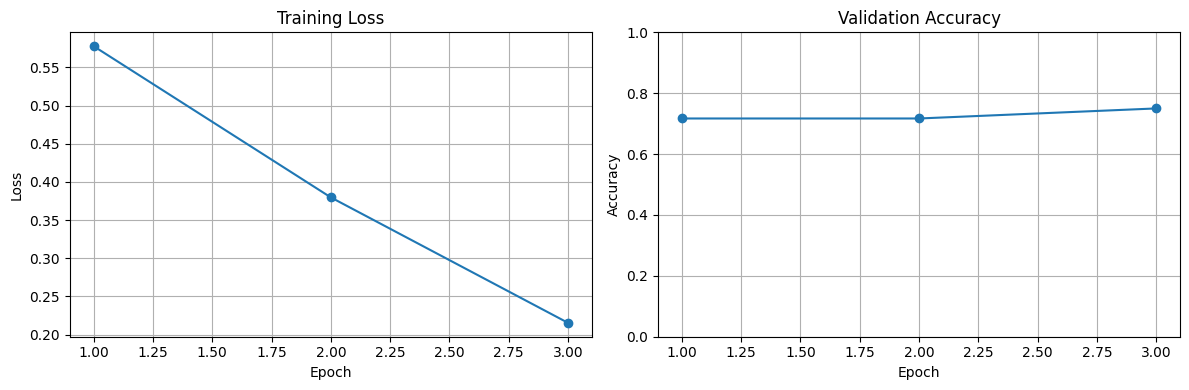

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, EPOCHS + 1), train_loss_history, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(range(1, EPOCHS + 1), validation_accuracy_history, marker="o")
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].grid(True)

plt.tight_layout()
plt.show()

Menampilkan grafik training loss dan validation accuracy.

Final validation accuracy: 0.7500

Classification report:
              precision    recall  f1-score   support

     Bearish       0.66      0.48      0.55        69
     Bullish       0.78      0.88      0.83       143

    accuracy                           0.75       212
   macro avg       0.72      0.68      0.69       212
weighted avg       0.74      0.75      0.74       212



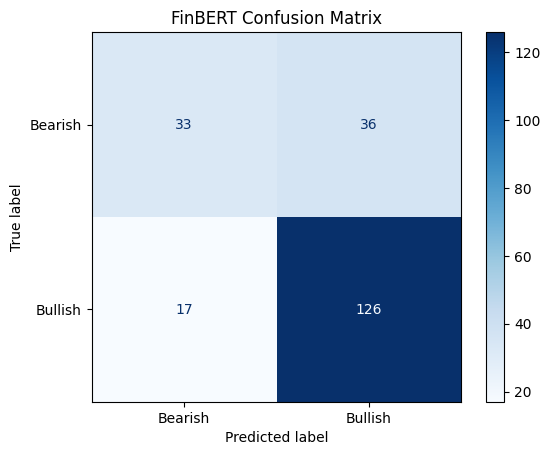

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Restore the built-in display function in case it was overwritten
from IPython.display import display

print("Final validation accuracy:", f"{validation_accuracy_history[-1]:.4f}")
print("\nClassification report:")
print(classification_report(
    val_true_labels,
    val_predictions,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(val_true_labels, val_predictions, labels=np.arange(num_labels))
# Renamed variable to 'cm_display' to avoid overwriting the built-in 'display' function
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("FinBERT Confusion Matrix")
plt.show()

Mengevaluasi hasil prediksi menggunakan accuracy, precision, recall, F1-score, dan confusion matrix.

In [31]:
def predict_sentiment(message):
    model.eval()
    inputs = tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=MAX_LEN
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits
        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_id = int(torch.argmax(probabilities).item())
    return {
        "message": message,
        "predicted_sentiment": label_encoder.inverse_transform([predicted_id])[0],
        "confidence": float(probabilities[predicted_id].item())
    }

predict_sentiment("The company reported strong revenue growth and higher profits.")

{'message': 'The company reported strong revenue growth and higher profits.',
 'predicted_sentiment': 'Bullish',
 'confidence': 0.9653451442718506}

Mencoba memprediksi sentimen dari pesan keuangan baru.